In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# plt.style.use('https://github.com/dhaitz/matplotlib-stylesheets/raw/master/pitayasmoothie-dark.mplstyle')
plt.rcParams.update({'font.family': 'serif'})

Deducción de la fórmula de cuota para un crédito hipotecario (no simple) con el método de amortización francés

Parámetros:
* $P$: Monto del crédito
* $I$: Intereses totales
* $C$: Cuota mensual
* $i$: Tasa de interés mensual
* $n$: Número de Cuotas

$$C = P \cdot \frac{i(1+i)^n}{(1+i)^n-1}$$
$$C = P \cdot i \cdot \frac{(1+i)^n}{(1+i)^n-1}$$
$$C = P \cdot i \cdot \frac{(1+i)^n-1+1}{(1+i)^n-1}$$
$$C = P \cdot i \left( 1+\frac{1}{(1+i)^n-1} \right)$$

Por otro lado,

$$P + I = n \cdot C$$
$$I = n \cdot C - P$$
$$I = n \cdot P \cdot i \left( 1+\frac{1}{(1+i)^n-1} \right) - P$$
$$I = P \left[ n \cdot i \cdot \left( 1+\frac{1}{(1+i)^n-1} \right) - 1 \right] $$

El valor $(1+i)^n-1$ se puede ver como un interes mensual acumulado total.

In [2]:
def format_currency(value):
    return f"${value:,.0f}"

def format_percentage(value, decimals=2):
    return f"{round(value * 100, decimals)}%"

In [3]:
def InteresMensual(IEF):
    return (1 + IEF)**(1/12) - 1

def InteresMensualAcumulado(i, n):
    return (1 + i)**n - 1

def CuotaMensual(P, i, n):
    return P * i * ( 1 + 1 / InteresMensualAcumulado(i, n) )

def TotalAPagar(P, i, n):
    return n * CuotaMensual(P, i, n)

def InteresTotal(P, i, n):
    return TotalAPagar(P, i, n) - P

In [4]:
def calc_data(P, i):
    data = pd.DataFrame(columns=["Plazo", "Cuota", "Total a pagar", "Interes total", "% de intereses", "% E.A.", "% E.A. Acumulado"])

    plazos_en_anios = [5, 10, 15, 20, 30]
    cuotas = []
    total_a_pagar = []
    interes_total = []
    porcentaje_de_intereses = []
    porcentaje_ea = []
    porcentaje_ea_acumulado = []

    for plazo in plazos_en_anios:
        n = plazo * 12  # Plazo en meses
        cuotas.append(CuotaMensual(P, i, n))
        total_a_pagar.append(TotalAPagar(P, i, n))
        interes_total.append(InteresTotal(P, i, n))
        porcentaje_de_intereses.append(interes_total[-1] / P)
        porcentaje_ea.append(porcentaje_de_intereses[-1] / plazo)
        porcentaje_ea_acumulado.append((1 + porcentaje_de_intereses[-1]) ** (1 / plazo) - 1)

    data["Plazo"] = plazos_en_anios
    data["Cuota"] = cuotas
    data["Total a pagar"] = total_a_pagar
    data["Interes total"] = interes_total
    data["% de intereses"] = porcentaje_de_intereses
    data["% E.A."] = porcentaje_ea
    data["% E.A. Acumulado"] = porcentaje_ea_acumulado

    data["Cuota"] = data["Cuota"].apply(format_currency)
    data["Total a pagar"] = data["Total a pagar"].apply(format_currency)
    data["Interes total"] = data["Interes total"].apply(format_currency)
    data["% de intereses"] = data["% de intereses"].apply(format_percentage)
    data["% E.A."] = data["% E.A."].apply(format_percentage)
    data["% E.A. Acumulado"] = data["% E.A. Acumulado"].apply(format_percentage)

    return data

In [5]:
valor = 400 * 1000000
porcentaje_credito = 1
interes_efectivo_anual = 0.06

interes_efectivo_mensual = InteresMensual(interes_efectivo_anual)
cuota_inicial = valor * (1 - porcentaje_credito)
monto = valor * porcentaje_credito

print(f"Valor de la propiedad: {format_currency(valor)}")
print(f"Cuota inicial: {format_currency(cuota_inicial)}")
print(f"Monto a financiar: {format_currency(monto)}")
print(f"Interes efectivo anual: {format_percentage(interes_efectivo_anual)}")
print(f"Interes efectivo mensual: {format_percentage(interes_efectivo_mensual, 4)}")
data = calc_data(monto, interes_efectivo_mensual)
print(data)

Valor de la propiedad: $400,000,000
Cuota inicial: $0
Monto a financiar: $400,000,000
Interes efectivo anual: 6.0%
Interes efectivo mensual: 0.4868%
   Plazo       Cuota Total a pagar Interes total % de intereses % E.A.   
0      5  $7,703,593  $462,215,593   $62,215,593         15.55%  3.11%  \
1     10  $4,408,961  $529,075,325  $129,075,325         32.27%  3.23%   
2     15  $3,341,176  $601,411,752  $201,411,752         50.35%  3.36%   
3     20  $2,829,168  $679,000,383  $279,000,383         69.75%  3.49%   
4     30  $2,357,482  $848,693,400  $448,693,400        112.17%  3.74%   

  % E.A. Acumulado  
0            2.93%  
1            2.84%  
2            2.76%  
3            2.68%  
4            2.54%  


In [6]:
monto = 400 * 1000000
meses = 60
interes_mensual = 0.005
interes_total = interes_mensual * meses
print(f'Interes total: {interes_total * 100}%')
total = monto * (1 + interes_total)
print(f'Total: {total:,.2f}')
cuota = total / meses
print(f'Cuota: {cuota:,.2f}')

Interes total: 30.0%
Total: 520,000,000.00
Cuota: 8,666,666.67


In [7]:
round((2.600) * 1000000) / (valor * porcentaje_credito) * 100 * 12

7.800000000000001

In [8]:
cuota = 1.284 * 1000000
ingresos = cuota / 0.3
print(f"Ingresos mínimos recomendados: {format_currency(ingresos)}")

Ingresos mínimos recomendados: $4,280,000


In [9]:
ingreso_m = 5.5 * 1000000
cuota = ingreso_m * 0.3
print(f"Cuota máxima recomendada: {format_currency(cuota)}")

Cuota máxima recomendada: $1,650,000


In [10]:
def calc_table(P, i, n, abonos=None):
    """
    Tabla de amortización (francés) con soporte de múltiples abonos a capital.
    
    Parámetros:
    - P: Principal del crédito
    - i: Tasa de interés mensual
    - n: Número de cuotas (meses)
    - abonos: Lista de diccionarios con formato:
        [{"mes": 12, "monto": 50000000, "tipo": "reduccion_plazo"}, ...]
        Tipos de abono:
        - "reduccion_plazo": mantiene la cuota, acorta el plazo
        - "reduccion_cuota": recalcula cuota menor, mantiene el plazo
    """
    Cuota_inicial = CuotaMensual(P, i, n)
    Total_inicial = TotalAPagar(P, i, n)

    # Normalizar abonos a un dict {mes: {"monto": float, "tipo": str}}
    abonos_map = {}
    if abonos is not None:
        for abono in abonos:
            mes = int(abono["mes"])
            monto = float(abono["monto"])
            tipo = abono.get("tipo", "reduccion_plazo")  # Por defecto reducción de plazo
            
            if mes in abonos_map:
                # Si ya existe un abono en ese mes, sumar montos
                abonos_map[mes]["monto"] += monto
                # Si hay tipos diferentes, usar el último especificado
                abonos_map[mes]["tipo"] = tipo
            else:
                abonos_map[mes] = {"monto": monto, "tipo": tipo}

    data = pd.DataFrame(columns=["Mes", "Cuota", "Intereses", "Amortización", "Saldo", "Total a pagar"])

    meses = list(range(1, n + 1))

    cuotas = []
    intereses = []
    amortizaciones = []
    saldos = []
    total_a_pagar = []

    saldo = P
    cuota_actual = Cuota_inicial
    total_restante = Total_inicial

    for mes in meses:
        # Calcular intereses sobre el saldo actual
        interes_mes = saldo * i
        
        # Calcular amortización normal (sin abono)
        amortizacion_normal = cuota_actual - interes_mes

        # Aplicar abono(s) del mes
        abono_info = abonos_map.get(mes, {"monto": 0.0, "tipo": "reduccion_plazo"})
        abono_mes = abono_info["monto"]
        tipo_abono = abono_info["tipo"]
        
        # La amortización total incluye el abono
        amortizacion_mes = amortizacion_normal + abono_mes

        # Actualizar saldo después de la amortización (incluyendo abono)
        saldo = saldo - amortizacion_mes

        # Registrar valores del mes actual
        cuotas.append(cuota_actual)
        intereses.append(interes_mes)
        amortizaciones.append(amortizacion_mes)
        saldos.append(saldo)

        # Actualizar Total a pagar: resta la cuota de este mes y el abono aplicado
        total_restante = max(total_restante - cuota_actual, 0)
        if abono_mes > 0:
            total_restante = max(total_restante - abono_mes, 0)
        total_a_pagar.append(total_restante)

        # Si se reduce cuota, recalcular para los meses restantes a partir del siguiente mes
        if abono_mes > 0 and tipo_abono == "reduccion_cuota":
            meses_restantes = max(n - mes, 0)
            if saldo > 0 and meses_restantes > 0:
                cuota_actual = CuotaMensual(saldo, i, meses_restantes)
            else:
                cuota_actual = 0

        # Cierre anticipado si el saldo quedó en cero o negativo
        if saldo <= 0:
            break

    # Acomodar tamaños
    meses = meses[:len(saldos)]

    data["Mes"] = meses
    data["Cuota"] = cuotas
    data["Intereses"] = intereses
    data["Amortización"] = amortizaciones
    data["Saldo"] = saldos
    data["Total a pagar"] = total_a_pagar

    return data

In [11]:
def show_data(data):
    copy_data = data.copy()
    copy_data["Cuota"] = copy_data["Cuota"].apply(format_currency)
    copy_data["Intereses"] = copy_data["Intereses"].apply(format_currency)
    copy_data["Amortización"] = copy_data["Amortización"].apply(format_currency)
    copy_data["Saldo"] = copy_data["Saldo"].apply(format_currency)
    copy_data["Total a pagar"] = copy_data["Total a pagar"].apply(format_currency)
    print(copy_data)

In [12]:
def show_plot(data, abonos=[]):
    data_copy = data.copy()
    plt.figure(figsize=(16, 8))
    meses_abono = [abono["mes"] for abono in abonos]
    if abonos is not None:
        data_copy.loc[data_copy["Mes"].isin(meses_abono), "Amortización"] = 0
    plt.title("Amortización de un crédito hipotecario con el método de amortización francés")
    plt.bar(data["Mes"], data["Intereses"], label="Intereses", color="red", alpha=0.5, width=0.5)
    plt.bar(data["Mes"], data_copy["Amortización"], bottom=data["Intereses"], label="Amortización", color="green", alpha=0.5, width=0.5)
    plt.legend()
    plt.show()

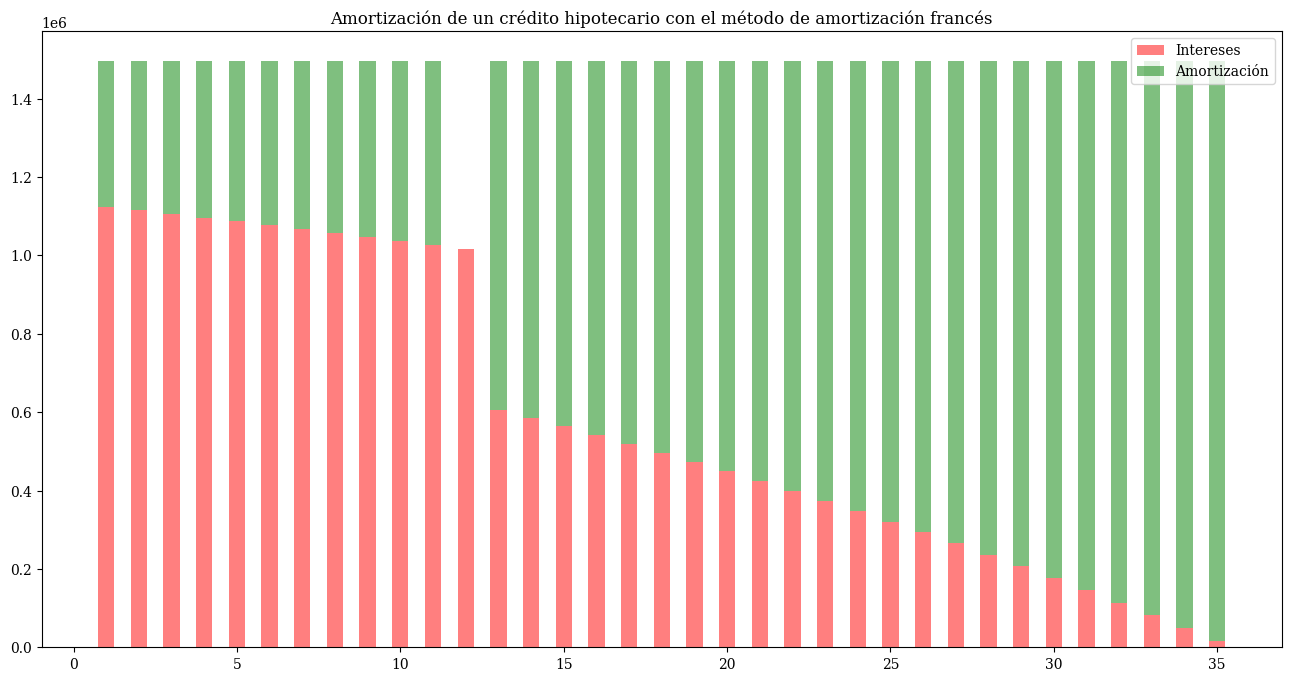

In [25]:
# Ejemplo básico sin abonos
monto = 48 * 1000000
interes_efectivo_anual = 0.32
plazo_en_anios = 5 * 12

abonos = [
    {"mes": 12, "monto": 17 * 1000000, "tipo": "reduccion_plazo"},
]

data = calc_table(monto, InteresMensual(interes_efectivo_anual), plazo_en_anios, abonos)
show_plot(data, abonos)


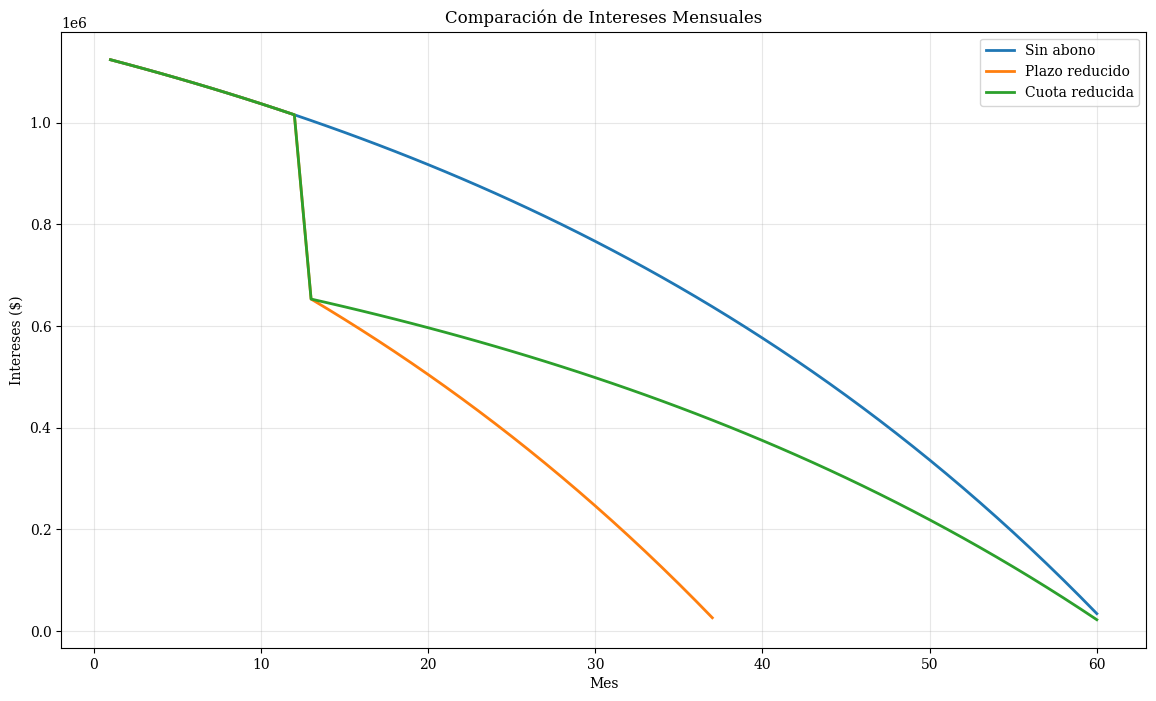

Monto: $48,000,000
Interes efectivo anual: 32.0% (2.3406% mensual)
Plazo en meses: 5 años (60 meses)
Cuota mensual: $1,497,035

=== RESUMEN DE AHORROS ===
--- Sin abono ---
Intereses: $41,822,086
Ahorro: $0 (0.0%)
Total abonos: $0
Relación ahorro-abono: nanx
Plazo: 5 años y 0 meses
--- Plazo reducido ---
Intereses: $22,035,510
Ahorro: $19,786,576 (47.31%)
Total abonos: $15,000,000
Relación ahorro-abono: 1.32x
Plazo: 3 años y 1 meses
--- Cuota reducida ---
Intereses: $31,692,755
Ahorro: $10,129,331 (24.22%)
Total abonos: $15,000,000
Relación ahorro-abono: 0.68x
Plazo: 5 años y 0 meses


/var/folders/fh/mk8v98mj0lv0vd10j2s5g2h40000gn/T/ipykernel_26970/868152590.py:92: RuntimeWarning: invalid value encountered in scalar divide
  print(f"Relación ahorro-abono: {(intereses_sin_abono - intereses_por_abono[key]) / total_abonos[key]:.2f}x")


In [45]:
monto = 48 * 1000000
interes_efectivo_anual = 0.32
plazo = 5 * 12

cuota = CuotaMensual(monto, InteresMensual(interes_efectivo_anual), plazo)

def calc_abonos(recurrencia: int, monto_abono: int, cantidad: int, tipo: str):
    """Se paga {monto_abono} cada {recurrencia} meses, {cantidad} veces

    Args:
        recurrencia (int): Número de meses entre cada pago
        monto_abono (int): Monto de cada pago
        cantidad (int): Número de pagos
        tipo (str): Tipo de abono

    Returns:
        list: Lista de diccionarios con formato:
            [{"mes": 12, "monto": 50000000, "tipo": "reduccion_plazo"}, ...]
    """
    abonos = []
    for i in range(1, cantidad + 1):
        abonos.append({"mes": i * recurrencia, "monto": monto_abono, "tipo": tipo})
    return abonos

abonos_dict = {
    "Sin abono": [],
    # f"1% Anual - {format_currency(monto * 0.01 / 12)}": calc_abonos(12, monto * 0.01, 15, "reduccion_plazo"),
    # f"2,5% Anual - {format_currency(monto * 0.025 / 12)}": calc_abonos(12, monto * 0.025, 12, "reduccion_plazo"),
    # f"3,6% Anual - {format_currency(monto * 0.036 / 12)}": calc_abonos(12, monto * 0.036, 12, "reduccion_plazo"),
    # f"5% Anual - {format_currency(monto * 0.05 / 12)}": calc_abonos(12, monto * 0.05, 9, "reduccion_plazo"),
    # f"10% Anual - {format_currency(monto * 0.1 / 12)}": calc_abonos(12, monto * 0.1, 6, "reduccion_plazo"),
    # f"10% Mensual - {format_currency(monto * 0.1 / 12)}": calc_abonos(1, monto * 0.1 / 12, 72, "reduccion_plazo"),
    # f"10% Anual (-1) - {format_currency(monto * 0.1 / 12)}": calc_abonos(12, monto * 0.1, 7, "reduccion_plazo")[1:],
    # f"10% Anual (-2) - {format_currency(monto * 0.1 / 12)}": calc_abonos(12, monto * 0.1, 8, "reduccion_plazo")[2:],
    "Plazo reducido": [
        {"mes": 12, "monto": 15 * 1000000, "tipo": "reduccion_plazo"},
    ],
    "Cuota reducida": [
        {"mes": 12, "monto": 15 * 1000000, "tipo": "reduccion_cuota"},
    ],
    # "Personalizado 2": calc_abonos(1, 4 * 1000000, 12, "reduccion_plazo")[8:],
    # f"Personalizado (-1) - {format_currency(monto * 0.1 / 12)}": [
    #     {"mes": 0, "monto": 0, "tipo": "reduccion_plazo"},
    #     {"mes": 24, "monto": monto * 0.2, "tipo": "reduccion_plazo"},
    #     {"mes": 36, "monto": monto * 0.1, "tipo": "reduccion_plazo"},
    #     {"mes": 48, "monto": monto * 0.05, "tipo": "reduccion_plazo"},
    #     {"mes": 60, "monto": monto * 0.05, "tipo": "reduccion_plazo"},
    #     {"mes": 72, "monto": monto * 0.05, "tipo": "reduccion_plazo"},
    # ],
    # f"15% Anual - {format_currency(monto * 0.15 / 12)}": calc_abonos(12, monto * 0.15, 4, "reduccion_plazo"),
}

data_por_abono = {}
for key, value in abonos_dict.items():
    data_por_abono[key] = calc_table(monto, InteresMensual(interes_efectivo_anual), plazo, value)

# Gráfica de intereses
plt.figure(figsize=(14, 8))
for key, value in data_por_abono.items():
    plt.plot(value['Mes'], value['Intereses'], label=key, linewidth=2)
plt.title('Comparación de Intereses Mensuales')
plt.xlabel('Mes')
plt.ylabel('Intereses ($)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Mostrar resumen de ahorros
intereses_por_abono = {}
for key, value in data_por_abono.items():
    intereses_por_abono[key] = value['Intereses'].sum()
total_abonos = {}
for key, value in abonos_dict.items():
    total_abonos[key] = sum([abono["monto"] for abono in value])
plazos_por_abono = {}
for key, value in data_por_abono.items():
    plazos_por_abono[key] = value['Mes'].max()

intereses_sin_abono = data_por_abono['Sin abono']['Intereses'].sum()

print(f"Monto: {format_currency(monto)}")
print(f"Interes efectivo anual: {format_percentage(interes_efectivo_anual)} ({format_percentage(InteresMensual(interes_efectivo_anual), 4)} mensual)")
print(f"Plazo en meses: {plazo // 12} años ({plazo} meses)")
print(f"Cuota mensual: {format_currency(cuota)}")

print("\n=== RESUMEN DE AHORROS ===")
for key, value in abonos_dict.items():
    print("---", key, "---")
    print(f"Intereses: ${intereses_por_abono[key]:,.0f}")
    print(f"Ahorro: ${intereses_sin_abono - intereses_por_abono[key]:,.0f} ({format_percentage((intereses_sin_abono - intereses_por_abono[key]) / intereses_sin_abono)})")
    print(f"Total abonos: ${total_abonos[key]:,.0f}")
    print(f"Relación ahorro-abono: {(intereses_sin_abono - intereses_por_abono[key]) / total_abonos[key]:.2f}x")
    print(f"Plazo: {plazos_por_abono[key] // 12} años y {plazos_por_abono[key] % 12} meses")


In [16]:
# Tarifas de impuesto predial unificado para vivienda residencial en Bogotá 2025
def tarifa_residencial(v):
    if v <= 176.611 * 1000000:
        return 0.55
    elif v <= 188.204 * 1000000:
        return 0.56
    elif v <= 216.665 * 1000000:
        return 0.57
    elif v <= 245.128 * 1000000:
        return 0.58
    elif v <= 273.591 * 1000000:
        return 0.59
    elif v <= 302.052 * 1000000:
        return 0.60
    elif v <= 330.514 * 1000000:
        return 0.61
    elif v <= 358.977 * 1000000:
        return 0.62
    elif v <= 406.413 * 1000000:
        return 0.63
    elif v <= 453.854 * 1000000:
        return 0.64
    elif v <= 501.289 * 1000000:
        return 0.65
    elif v <= 548.727 * 1000000:
        return 0.66
    elif v <= 596.163 * 1000000:
        return 0.68
    elif v <= 643.601 * 1000000:
        return 0.70
    elif v <= 691.037 * 1000000:
        return 0.72
    elif v <= 738.475 * 1000000:
        return 0.74
    elif v <= 785.912 * 1000000:
        return 0.76
    elif v <= 852.324 * 1000000:
        return 0.78
    elif v <= 918.737 * 1000000:
        return 0.80
    elif v <= 985.147 * 1000000:
        return 0.82
    elif v <= 1051.562 * 1000000:
        return 0.84
    elif v <= 1117.971 * 1000000:
        return 0.86
    elif v <= 1184.383 * 1000000:
        return 0.88
    elif v <= 1250.796 * 1000000:
        return 0.90
    elif v <= 1317.208 * 1000000:
        return 0.92
    elif v <= 1554.392 * 1000000:
        return 0.95
    elif v <= 1791.582 * 1000000:
        return 1.01
    elif v <= 2028.768 * 1000000:
        return 1.08
    elif v <= 2276.985 * 1000000:
        return 1.15
    else:
        return 1.23

# Según la resolución SDH - 000301 del 26 de diciembre del 2024
# Link: https://back.haciendabogota.gov.co/sites/default/files/normatividad/resolucion/RESOLUCION%20SDH%20-%20000301%20DE%202024%20-%20Resolución%20Rangos%20de%20Avalúo%20Catastral%202025%2010122024.pdf

# NOTA: Si se paga antes de la fecha límite, hay un descuento del 10% en el impuesto. Si se paga después, se pagan intereses de mora.

In [17]:
# El seguro de hogar depende de varios factores, las aseguradoras suelen aplicar tarifas entre el 0.05% y el 0.3% del valor del inmueble anualmente.
tarifa_seguro_hogar = 0.15

# El seguro de vida del crédito hipotecario suele estar entre el 0.03% y el 0.08% del monto del crédito mensualmente.
tarifa_seguro_vida = 0.05 * 12

In [18]:
# Costos de tener un inmueble
valor = 195 * 1000000
monto = valor * 0.7  # 80% del valor

tarifa_impuesto = tarifa_residencial(valor)
impuesto = valor * tarifa_impuesto * 0.01
seguro_hogar = valor * tarifa_seguro_hogar * 0.01
seguro_vida = monto * tarifa_seguro_vida * 0.01
total = impuesto + seguro_hogar + seguro_vida

print("\n=== COSTOS DE TENER UN INMUEBLE ===")
print(f"Valor del inmueble: {format_currency(valor)}")
print(f"Impuesto predial unificado anual: {format_currency(impuesto)} ({tarifa_impuesto}%) - {format_currency(impuesto / 12)} mensual")
print(f"Seguro de hogar anual: {format_currency(seguro_hogar)} ({tarifa_seguro_hogar}%) - {format_currency(seguro_hogar / 12)} mensual")
print(f"Monto del crédito (70% del valor): {format_currency(monto)}")
print(f"Seguro de vida anual: {format_currency(seguro_vida)} ({round(tarifa_seguro_vida, 2)}%) - {format_currency(seguro_vida / 12)} mensual")
print(f"Aporte total: {format_currency(total)} - {format_currency(total / 12)} mensual")


=== COSTOS DE TENER UN INMUEBLE ===
Valor del inmueble: $195,000,000
Impuesto predial unificado anual: $1,111,500 (0.57%) - $92,625 mensual
Seguro de hogar anual: $292,500 (0.15%) - $24,375 mensual
Monto del crédito (70% del valor): $136,500,000
Seguro de vida anual: $819,000 (0.6%) - $68,250 mensual
Aporte total: $2,223,000 - $185,250 mensual
